# ĐỒ ÁN MÔN HỌC: KHAI PHÁ DỮ LIỆU (DATA MINING)
## ĐỀ TÀI: PHÁT HIỆN TIN GIẢ DỰA TRÊN TẬP DỮ LIỆU LIAR2 (FAKE NEWS DETECTION)
### 🚀 BẢN TỐI ƯU TOÀN DIỆN: PHÂN LOẠI 3 MỨC CHUẨN POLITIFACT & HỌC KẾT HỢP (ENSEMBLE)

---

### 👥 PHÂN CHIA NHIỆM VỤ ĐỒ ÁN (3 THÀNH VIÊN):
* **👤 THÀNH VIÊN 1: Hiểu Dữ liệu, Kiểm soát Rò rỉ Dữ liệu & Tiền xử lý NLP**
  * *Nhiệm vụ*: Phân tích cấu trúc dữ liệu LIAR2; Kiểm soát rò rỉ dữ liệu trực tiếp (loại bỏ hoàn toàn cột `justification` và `id`); Thiết lập chiến lược gộp nhãn 3 mức chuẩn PolitiFact (3-1-2: False gồm `pants-fire`, `false`, `barely-true`; Mixed gồm `half-true`; True gồm `mostly-true`, `true`); Tiền xử lý NLP chuyên sâu (Chuẩn hóa ký tự nháy, mở rộng từ viết tắt *Contractions* và **bảo tồn tuyệt đối từ phủ định** `not`, `no`, `never`).
  * *Phụ trách*: **PHẦN 1 (Cell 1 đến Cell 4)**.

* **👤 THÀNH VIÊN 2: Kỹ thuật Kỹ sư Đặc trưng Đa chiều (Feature Engineering)**
  * *Nhiệm vụ*: Trích xuất hệ thống đặc trưng cú pháp và tâm lý giật gân (*Stylometrics*: `all_caps_ratio`, `num_exclamations`, `word_count`, `num_numbers`); Thiết kế 2 chỉ số uy tín người nói cốt lõi (*Trust Score*, *Net Truth* bao hàm đầy đủ các bậc sự thật); Vector hóa TF-IDF N-gram (1, 2) trên văn bản kết hợp ngữ cảnh đa tầng; Nghiên cứu cắt bỏ đặc trưng tích lũy (*Ablation Study* 5 chặng chạy thực nghiệm nhất quán).
  * *Phụ trách*: **PHẦN 2 (Cell 5 đến Cell 7)**.

* **👤 THÀNH VIÊN 3: Mô hình hóa, Tối ưu Siêu mô hình Ensemble trên Validation & Đánh giá Lỗi**
  * *Nhiệm vụ*: Thiết lập mô hình cơ sở Baseline (TF-IDF thuần câu chữ); Huấn luyện các mô hình đa đặc trưng (Logistic Regression, Random Forest, XGBoost); Tối ưu hóa trọng số Siêu mô hình Weighted Soft Voting Ensemble trên tập Validation nhằm triệt tiêu rò rỉ tập Test; Đánh giá thực nghiệm mức độ phụ thuộc vào lịch sử người nói; Phân tích ma trận nhầm lẫn và lỗi đảo cực; Trích xuất Feature Importance thực tế từ XGBoost; Đóng gói hàm demo `predict_statement()`.
  * *Phụ trách*: **PHẦN 3 & PHẦN 4 (Cell 8 đến Cell 13)**.

---


In [1]:
# 1. Cài đặt và Import toàn bộ thư viện cần thiết
import pandas as pd
import numpy as np
import os
import sys
import re
import json
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

# Cố định seed ngẫu nhiên cho toàn bộ quy trình thực nghiệm (Reproducibility)
np.random.seed(42)
print('✅ Đã nạp thành công toàn bộ thư viện và cố định Random Seed = 42!')


✅ Đã nạp thành công toàn bộ thư viện và cố định Random Seed = 42!


In [2]:
# 2. Đọc dữ liệu với cơ chế nạp thông minh (Tự động nhận diện Colab / Local / Drive)
def load_liar2_data():
    local_paths = [
        ('liar2_extracted/liar2-main/liar2/train.csv', 'liar2_extracted/liar2-main/liar2/valid.csv', 'liar2_extracted/liar2-main/liar2/test.csv'),
        ('liar2-main/liar2-main/liar2/train.csv', 'liar2-main/liar2-main/liar2/valid.csv', 'liar2-main/liar2-main/liar2/test.csv'),
        ('/content/drive/MyDrive/fake/train.csv', '/content/drive/MyDrive/fake/valid.csv', '/content/drive/MyDrive/fake/test.csv'),
        ('train.csv', 'valid.csv', 'test.csv')
    ]
    for tr, val, te in local_paths:
        if os.path.exists(tr) and os.path.exists(val) and os.path.exists(te):
            print(f"📂 Đang nạp dữ liệu từ đường dẫn cục bộ: '{tr}'")
            return pd.read_csv(tr), pd.read_csv(val), pd.read_csv(te)
    
    print('🌐 Tải trực tiếp bộ dữ liệu LIAR2 từ HuggingFace...')
    from datasets import load_dataset
    ds = load_dataset('chengxuphd/liar2')
    return ds['train'].to_pandas(), ds['validation'].to_pandas(), ds['test'].to_pandas()

train_df, val_df, test_df = load_liar2_data()
print(f'📊 Kích thước ban đầu: Train={train_df.shape}, Valid={val_df.shape}, Test={test_df.shape}')


📂 Đang nạp dữ liệu từ đường dẫn cục bộ: 'liar2_extracted/liar2-main/liar2/train.csv'
📊 Kích thước ban đầu: Train=(18369, 16), Valid=(2297, 16), Test=(2296, 16)


## PHẦN 1 : KIỂM SOÁT RÒ RỈ DỮ LIỆU & TIỀN XỬ LÝ NLP CHUYÊN SÂU
> **Trọng tâm**: Loại bỏ cột rò rỉ `justification` và `id`; Ánh xạ 3 nhãn chuẩn PolitiFact; Tiền xử lý NLP mở rộng viết tắt và bảo tồn từ phủ định.


In [3]:
# 1. Kiểm soát Rò rỉ Dữ liệu Trực tiếp (Loại bỏ cột 'justification' và 'id')
# Cột 'justification' là bài phân tích của nhà báo viết sau khi kiểm chứng, chứa sẵn đáp án ('We rate this False...').
# Cột 'id' là mã định danh kỹ thuật ngẫu nhiên, không có giá trị học máy.
drop_leak_cols = [c for c in ['justification', 'id'] if c in train_df.columns]
train_df = train_df.drop(columns=drop_leak_cols)
val_df   = val_df.drop(columns=drop_leak_cols)
test_df  = test_df.drop(columns=drop_leak_cols)
print(f'✅ Đã xóa bỏ các cột rò rỉ trực tiếp: {drop_leak_cols}')

# 2. Chiến lược gộp 3 nhãn chuẩn PolitiFact (Chiến lược 3-1-2)
# 0: pants-fire, 1: false, 2: barely-true -> Gom vào Nhóm 0 (FALSE - Sai sự thật / Bịa đặt)
# 3: half-true -> Giữ riêng làm Nhóm 1 (MIXED - Nửa đúng nửa sai / Lập lờ)
# 4: mostly-true, 5: true -> Gom vào Nhóm 2 (TRUE - Sự thật có kiểm chứng)
def map_to_3way(val):
    if isinstance(val, str):
        v = val.strip().lower()
        if v in ['pants-fire', 'pants-on-fire', 'false', 'barely-true', '0', '1', '2']:
            return 0
        elif v in ['half-true', '3']:
            return 1
        elif v in ['mostly-true', 'true', '4', '5']:
            return 2
    elif isinstance(val, (int, float, np.integer)):
        if val in [0, 1, 2]: return 0
        elif val == 3: return 1
        elif val in [4, 5]: return 2
    raise ValueError(f'Phát hiện giá trị nhãn không hợp lệ trong dữ liệu: {val}')

train_df['label_3way'] = train_df['label'].apply(map_to_3way)
val_df['label_3way']   = val_df['label'].apply(map_to_3way)
test_df['label_3way']  = test_df['label'].apply(map_to_3way)

print('\n===== PHÂN BỐ 3 NHÃN TRÊN TẬP TRAIN (18.369 MẪU) =====')
dist = train_df['label_3way'].value_counts().sort_index()
for k, name in [(0, '0: FALSE (Sai lệch)'), (1, '1: MIXED (Nửa đúng sai)'), (2, '2: TRUE (Sự thật)')]:
    print(f'  + {name:25s}: {dist[k]} mẫu ({dist[k]/len(train_df)*100:.1f}%)')

# Tính Majority baseline trên tập Test (Lớp đa số FALSE)
majority_test_acc = (test_df['label_3way'] == 0).mean() * 100
print(f'📌 Majority Baseline trên tập Test (Luôn đoán nhãn 0 FALSE): {majority_test_acc:.2f}% ({sum(test_df["label_3way"]==0)}/{len(test_df)} mẫu)')


✅ Đã xóa bỏ các cột rò rỉ trực tiếp: ['justification', 'id']

===== PHÂN BỐ 3 NHÃN TRÊN TẬP TRAIN (18.369 MẪU) =====
  + 0: FALSE (Sai lệch)      : 10591 mẫu (57.7%)
  + 1: MIXED (Nửa đúng sai)  : 2967 mẫu (16.2%)
  + 2: TRUE (Sự thật)        : 4811 mẫu (26.2%)
📌 Majority Baseline trên tập Test (Luôn đoán nhãn 0 FALSE): 57.62% (1323/2296 mẫu)


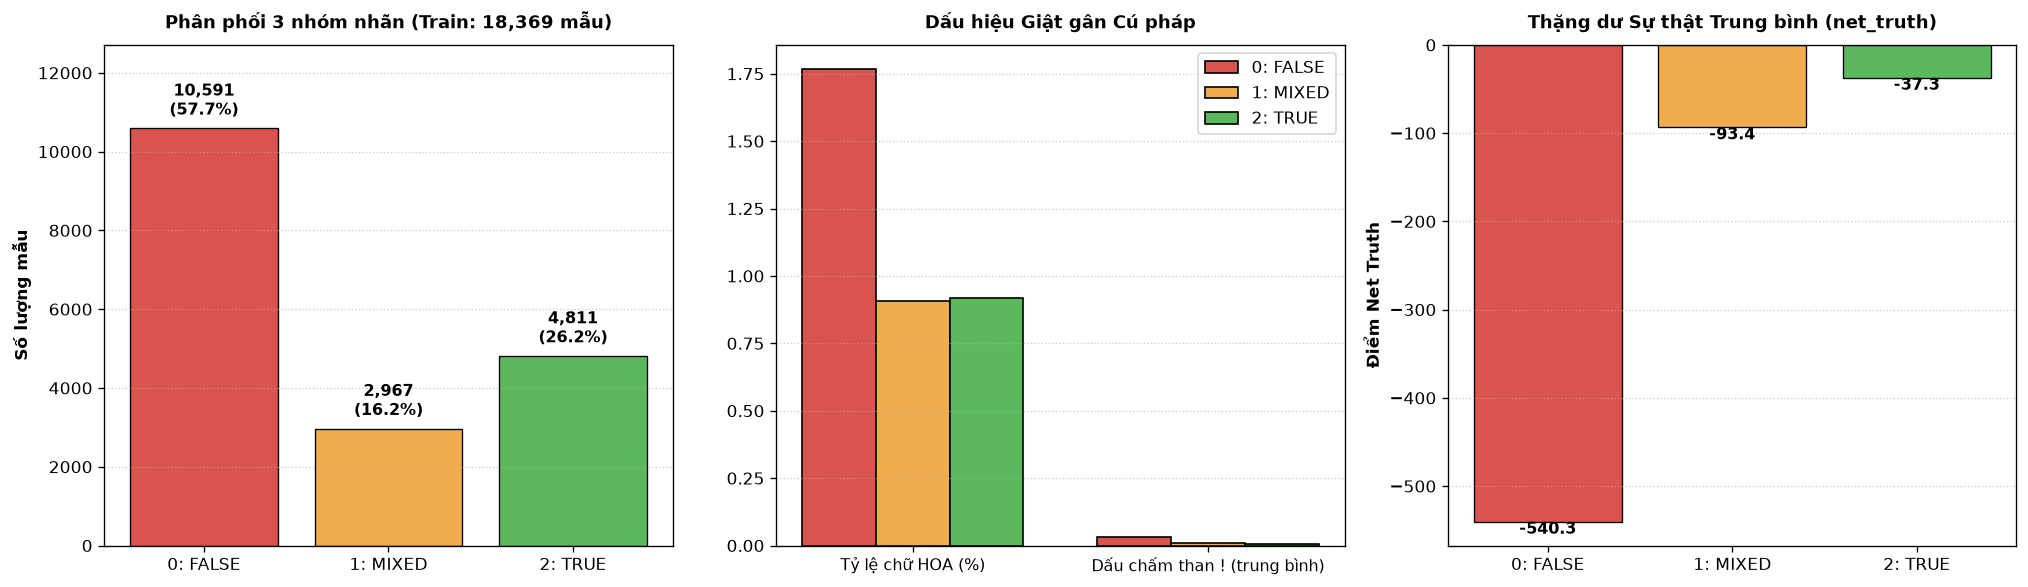

In [4]:
# 2. Trực quan hóa Phân phối 3 Nhãn & Dấu hiệu Tâm lý Giật gân (EDA tính động 100%)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
labels = ['0: FALSE', '1: MIXED', '2: TRUE']
train_counts = [len(train_df[train_df['label_3way']==0]), len(train_df[train_df['label_3way']==1]), len(train_df[train_df['label_3way']==2])]
colors = ['#d9534f', '#f0ad4e', '#5cb85c']

# Subplot 1: Phân phối số lượng mẫu
axes[0].bar(labels, train_counts, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title(f'Phân phối 3 nhóm nhãn (Train: {len(train_df):,} mẫu)', fontsize=11, fontweight='bold', pad=10)
axes[0].set_ylabel('Số lượng mẫu', fontsize=10, fontweight='bold')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
max_c = max(train_counts)
axes[0].set_ylim(0, max_c * 1.2)
for i, v in enumerate(train_counts):
    pct = v / sum(train_counts) * 100
    axes[0].text(i, v + max_c * 0.02, f'{v:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Tính toán đặc trưng trực tiếp từ train_df
raw_s_tr = train_df['statement'].astype(str)
eda_wc = raw_s_tr.apply(lambda x: max(1, len(x.split())))
eda_caps = raw_s_tr.apply(lambda x: sum(1 for w in x.split() if w.isupper() and len(w) > 1)) / eda_wc * 100
eda_excl = raw_s_tr.apply(lambda x: x.count('!'))
eda_true = pd.to_numeric(train_df['true_counts'], errors='coerce').fillna(0) + pd.to_numeric(train_df['mostly_true_counts'], errors='coerce').fillna(0)
eda_false = pd.to_numeric(train_df['false_counts'], errors='coerce').fillna(0) + pd.to_numeric(train_df['pants_on_fire_counts'], errors='coerce').fillna(0) + pd.to_numeric(train_df['mostly_false_counts'], errors='coerce').fillna(0)
eda_net_truth = eda_true - eda_false

eda_df = pd.DataFrame({'label_3way': train_df['label_3way'], 'caps': eda_caps, 'excl': eda_excl, 'net_truth': eda_net_truth})
eda_stats = eda_df.groupby('label_3way').mean()

# Subplot 2: Cú pháp giật gân (caps % và excl)
x2 = np.arange(2)
w2 = 0.25
for idx_label, col_c in enumerate(colors):
    vals = [eda_stats.loc[idx_label, 'caps'], eda_stats.loc[idx_label, 'excl']]
    axes[1].bar(x2 + (idx_label - 1) * w2, vals, w2, label=labels[idx_label], color=col_c, edgecolor='black')
axes[1].set_title('Dấu hiệu Giật gân Cú pháp', fontsize=11, fontweight='bold', pad=10)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(['Tỷ lệ chữ HOA (%)', 'Dấu chấm than ! (trung bình)'], fontsize=9.5)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

# Subplot 3: Thặng dư sự thật net_truth (Thang đo riêng biệt, không bị bẹp)
net_vals = [eda_stats.loc[0, 'net_truth'], eda_stats.loc[1, 'net_truth'], eda_stats.loc[2, 'net_truth']]
bars3 = axes[2].bar(labels, net_vals, color=colors, edgecolor='black', linewidth=0.8)
axes[2].set_title('Thặng dư Sự thật Trung bình (net_truth)', fontsize=11, fontweight='bold', pad=10)
axes[2].set_ylabel('Điểm Net Truth', fontsize=10, fontweight='bold')
axes[2].grid(axis='y', linestyle=':', alpha=0.6)
axes[2].axhline(0, color='black', linewidth=1.0)
for b in bars3:
    y = b.get_height()
    va = 'bottom' if y >= 0 else 'top'
    axes[2].text(b.get_x() + b.get_width()/2, y, f'{y:.1f}', ha='center', va=va, fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()


In [5]:
# 3. Tiền xử lý văn bản NLP chuẩn Fact-checking: Mở rộng Contractions & Bảo tồn Từ phủ định
CONTRACTIONS = {
    "can't": "cannot", "won't": "will not",
    "don't": "do not", "didn't": "did not", "doesn't": "does not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not",
    "couldn't": "could not", "shouldn't": "should not", "wouldn't": "would not",
    "isn't": "is not", "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "i'm": "i am", "you're": "you are", "he's": "he is", "she's": "she is",
    "it's": "it is", "we're": "we are", "they're": "they are",
    "i've": "i have", "you've": "you have", "we've": "we have", "they've": "they have",
    "i'll": "i will", "you'll": "you will", "he'll": "he will", "she'll": "she will",
    "we'll": "we will", "they'll": "they will"
}

def clean_text_nlp(text):
    """
    Tiền xử lý văn bản bảo tồn ngữ nghĩa Fact-checking:
    1. Chuyển chữ thường, chuẩn hóa dấu nháy cong (‘, ’, “, ”).
    2. Mở rộng từ viết tắt dùng Regex Word Boundary (\b).
    3. Xử lý hậu tố n't còn sót lại.
    4. Bảo tồn nguyên vẹn dấu chấm than (!), dấu hỏi (?) và từ phủ định (not, no, never).
    """
    text = str(text).lower()
    text = text.replace('’', "'").replace('‘', "'").replace('“', '"').replace('”', '"')
    for contraction, expanded in CONTRACTIONS.items():
        pattern = r'\b' + re.escape(contraction) + r'\b'
        text = re.sub(pattern, expanded, text, flags=re.IGNORECASE)
    text = re.sub(r"\bn't\b|(?<=\w)n't\b", " not", text, flags=re.IGNORECASE)
    text = re.sub(r'[^a-z0-9\s!\?]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print('📝 Minh họa quy trình tiền xử lý bảo tồn từ phủ định:')
demo_sample = "Obama didn’t increase taxes, and won’t do it!"
print(f'   Câu gốc    : {demo_sample}')
print(f'   Đã xử lý   : {clean_text_nlp(demo_sample)}')


📝 Minh họa quy trình tiền xử lý bảo tồn từ phủ định:
   Câu gốc    : Obama didn’t increase taxes, and won’t do it!
   Đã xử lý   : obama did not increase taxes and will not do it!


## PHẦN 2 : KỸ THUẬT KỸ SƯ ĐẶC TRƯNG ĐA CHIỀU (FEATURE ENGINEERING)
> **Trọng tâm**: Trích xuất Stylometrics, điểm Uy tín người nói (`trust_score`, `net_truth`); Xây dựng ColumnTransformer 25.013 chiều.


In [6]:
# 1. Trích xuất Đặc trưng Cú pháp Giật gân (Stylometrics) & Chỉ số Uy tín Người nói
EXTREME_WORDS = set(['always', 'never', 'worst', 'greatest', 'massive', 'disaster', 'destroy', 'radical', 'corrupt', 'lie', 'fraud', 'illegal'])

def extract_advanced_features(df):
    d = df.copy()
    raw_s = d['statement'].astype(str)
    d['clean_statement'] = d['statement'].apply(clean_text_nlp)
    
    # 1. Cú pháp & Dấu hiệu giật gân
    d['word_count'] = raw_s.apply(lambda x: max(1, len(x.split())))
    d['all_caps_ratio'] = raw_s.apply(lambda x: sum(1 for w in x.split() if w.isupper() and len(w) > 1)) / d['word_count']
    d['num_exclamations'] = raw_s.apply(lambda x: x.count('!'))
    # Đếm số lượng từ số bằng regex word boundary
    d['num_numbers'] = raw_s.apply(lambda x: len(re.findall(r'\b\d+\b', x)))
    d['extreme_words_count'] = d['clean_statement'].apply(lambda x: sum(1 for w in x.split() if w in EXTREME_WORDS))
    
    # 2. Chuẩn hóa các cột lịch sử người nói (6 cột trong LIAR2)
    hist_cols = ['true_counts', 'mostly_true_counts', 'half_true_counts', 'mostly_false_counts', 'false_counts', 'pants_on_fire_counts']
    for c in hist_cols:
        d[c] = pd.to_numeric(d[c], errors='coerce').fillna(0)
    
    # 3. Hai chỉ số uy tín bản chất: Trust Score & Net Truth (Bao hàm đầy đủ mostly_false_counts)
    total_hist = d['true_counts'] + d['mostly_true_counts'] + d['half_true_counts'] + d['mostly_false_counts'] + d['false_counts'] + d['pants_on_fire_counts']
    d['trust_score'] = (d['mostly_true_counts'] + d['true_counts']) / (total_hist + 1.0)
    d['net_truth'] = (d['mostly_true_counts'] + d['true_counts']) - (d['mostly_false_counts'] + d['false_counts'] + d['pants_on_fire_counts'])
    
    # 4. Văn bản tổng hợp đa ngữ cảnh (Combined text)
    for c in ['speaker', 'subject', 'context']:
        d[c] = d[c].fillna('unknown').astype(str)
    d['combined_text'] = d['clean_statement'] + ' ' + d['speaker'] + ' ' + d['subject'] + ' ' + d['context']
    return d

train_feat = extract_advanced_features(train_df)
val_feat   = extract_advanced_features(val_df)
test_feat  = extract_advanced_features(test_df)

print('===== GIÁ TRỊ TRUNG BÌNH CÁC ĐẶC TRƯNG TÍNH THẬT GIỮA 3 NHÓM NHÃN =====')
cue_summary = train_feat.groupby('label_3way')[['all_caps_ratio', 'num_exclamations', 'extreme_words_count', 'trust_score', 'net_truth']].mean()
cue_summary.index = ['0: FALSE', '1: MIXED', '2: TRUE']
print(cue_summary.round(4))


===== GIÁ TRỊ TRUNG BÌNH CÁC ĐẶC TRƯNG TÍNH THẬT GIỮA 3 NHÓM NHÃN =====
          all_caps_ratio  num_exclamations  ...  trust_score  net_truth
0: FALSE          0.0177            0.0303  ...       0.1270  -540.3144
1: MIXED          0.0091            0.0094  ...       0.2371   -93.3515
2: TRUE           0.0092            0.0039  ...       0.4207   -37.2588

[3 rows x 5 columns]


In [7]:
# 2. Xây dựng ColumnTransformer và Fit duy nhất trên tập Train
num_cols = ['true_counts', 'mostly_true_counts', 'half_true_counts', 'mostly_false_counts', 'false_counts', 'pants_on_fire_counts',
            'word_count', 'all_caps_ratio', 'num_exclamations', 'num_numbers', 'extreme_words_count', 'trust_score', 'net_truth']

preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=25000, ngram_range=(1, 2), sublinear_tf=True), 'combined_text'),
        ('num', StandardScaler(), num_cols)
    ],
    remainder='drop'
)

# FIT DUY NHẤT TRÊN TẬP TRAIN (Chống rò rỉ dữ liệu qua phân phối toàn cục)
X_train_multi = preprocessor.fit_transform(train_feat)
X_val_multi   = preprocessor.transform(val_feat)
X_test_multi  = preprocessor.transform(test_feat)

y_train = train_feat['label_3way'].values
y_val   = val_feat['label_3way'].values
y_test  = test_feat['label_3way'].values

print(f'✅ Ma trận đặc trưng hoàn chỉnh đã sẵn sàng (Đúng {X_train_multi.shape[1]:,} chiều):')
print(f'   Train : {X_train_multi.shape}')
print(f'   Valid : {X_val_multi.shape}')
print(f'   Test  : {X_test_multi.shape}')


✅ Ma trận đặc trưng hoàn chỉnh đã sẵn sàng (Đúng 25,013 chiều):
   Train : (18369, 25013)
   Valid : (2297, 25013)
   Test  : (2296, 25013)


## PHẦN 3 : MÔ HÌNH HÓA, TỐI ƯU ENSEMBLE TRÊN VALIDATION & ĐÁNH GIÁ LỖI
> **Trọng tâm**: Baseline TF-IDF; Mô hình đa đặc trưng; Tối ưu trọng số Ensemble trên Validation; Thí nghiệm kiểm tra rò rỉ lịch sử người nói; Phân tích lỗi và Feature Importance.


In [8]:
# 1. Huấn luyện Mô hình Baseline (Chỉ sử dụng Văn bản TF-IDF thuần túy)
tfidf_base = TfidfVectorizer(max_features=25000, ngram_range=(1, 2), sublinear_tf=True)
X_train_base = tfidf_base.fit_transform(train_feat['clean_statement'])
X_val_base   = tfidf_base.transform(val_feat['clean_statement'])
X_test_base  = tfidf_base.transform(test_feat['clean_statement'])

# Baseline 1: Logistic Regression (Cấu hình nhất quán C=1.5, max_iter=2000)
lr_base = LogisticRegression(C=1.5, max_iter=2000, class_weight='balanced', random_state=42)
lr_base.fit(X_train_base, y_train)
acc_lr_base_val = accuracy_score(y_val, lr_base.predict(X_val_base))
acc_lr_base = accuracy_score(y_test, lr_base.predict(X_test_base))
f1_lr_base = f1_score(y_test, lr_base.predict(X_test_base), average='macro')

# Baseline 2: Linear SVM
svm_base = LinearSVC(class_weight='balanced', random_state=42)
svm_base.fit(X_train_base, y_train)
acc_svm_base_val = accuracy_score(y_val, svm_base.predict(X_val_base))
acc_svm_base = accuracy_score(y_test, svm_base.predict(X_test_base))
f1_svm_base = f1_score(y_test, svm_base.predict(X_test_base), average='macro')

print('===== KẾT QUẢ MÔ HÌNH BASELINE (TEXT-ONLY TF-IDF) TRÊN TẬP TEST =====')
print(f'1. Logistic Regression Baseline : Accuracy = {acc_lr_base*100:.2f}% | Val = {acc_lr_base_val*100:.2f}% | Macro F1 = {f1_lr_base:.4f}')
print(f'2. Linear SVM Baseline          : Accuracy = {acc_svm_base*100:.2f}% | Val = {acc_svm_base_val*100:.2f}% | Macro F1 = {f1_svm_base:.4f}')
majority_acc = (y_test == 0).mean() * 100
print(f'-> Nhận xét học thuật: Mô hình cơ sở TF-IDF đạt Accuracy {acc_lr_base*100:.2f}% (Macro F1 = {f1_lr_base:.4f}), xấp xỉ mức đoán theo lớp đa số Majority ({majority_acc:.2f}%).')
print('   Điều này cho thấy văn bản đơn thuần chưa đủ để phân biệt các phát biểu chính trị phức tạp, cần bổ sung hệ thống đặc trưng đa tầng.')


===== KẾT QUẢ MÔ HÌNH BASELINE (TEXT-ONLY TF-IDF) TRÊN TẬP TEST =====
1. Logistic Regression Baseline : Accuracy = 58.23% | Val = 56.25% | Macro F1 = 0.5084
2. Linear SVM Baseline          : Accuracy = 57.88% | Val = 56.77% | Macro F1 = 0.4754
-> Nhận xét học thuật: Mô hình cơ sở TF-IDF đạt Accuracy 58.23% (Macro F1 = 0.5084), xấp xỉ mức đoán theo lớp đa số Majority (57.62%).
   Điều này cho thấy văn bản đơn thuần chưa đủ để phân biệt các phát biểu chính trị phức tạp, cần bổ sung hệ thống đặc trưng đa tầng.


In [9]:
# 2. Huấn luyện các Siêu Mô hình Đa đặc trưng và Tối ưu hóa Siêu mô hình Ensemble trên Validation
print('>>> GIAI ĐOẠN 2: Huấn luyện các mô hình Đa đặc trưng...')

# 2.1 Logistic Regression Đa đặc trưng (Cùng cấu hình C=1.5, max_iter=2000)
lr_multi = LogisticRegression(C=1.5, max_iter=2000, class_weight='balanced', random_state=42)
lr_multi.fit(X_train_multi, y_train)
acc_lr_m_val = accuracy_score(y_val, lr_multi.predict(X_val_multi))
acc_lr_m = accuracy_score(y_test, lr_multi.predict(X_test_multi))
gain_lr = (acc_lr_m - acc_lr_base) * 100
print(f'  + Logistic Regression Multi-feature: Test Acc = {acc_lr_m*100:.2f}% | Val = {acc_lr_m_val*100:.2f}% (Tăng +{gain_lr:.2f} điểm % so với Baseline)')

# 2.2 Random Forest Multi-feature
rf_multi = RandomForestClassifier(n_estimators=150, max_depth=16, class_weight='balanced', random_state=42, n_jobs=-1)
rf_multi.fit(X_train_multi, y_train)
acc_rf_m_val = accuracy_score(y_val, rf_multi.predict(X_val_multi))
acc_rf_m = accuracy_score(y_test, rf_multi.predict(X_test_multi))
print(f'  + Random Forest Multi-feature       : Test Acc = {acc_rf_m*100:.2f}% | Val = {acc_rf_m_val*100:.2f}%')

# 2.3 XGBoost Multi-feature
xgb_multi = xgb.XGBClassifier(n_estimators=200, learning_rate=0.08, max_depth=6, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_multi.fit(X_train_multi, y_train)
acc_xgb_m_val = accuracy_score(y_val, xgb_multi.predict(X_val_multi))
acc_xgb_m = accuracy_score(y_test, xgb_multi.predict(X_test_multi))
print(f'  + XGBoost Multi-feature             : Test Acc = {acc_xgb_m*100:.2f}% | Val = {acc_xgb_m_val*100:.2f}%')

# 2.4 Siêu mô hình Học kết hợp: TỐI ƯU HÓA TRỌNG SỐ SOFT VOTING TRÊN VALIDATION (Zero Test Leakage)
p_rf_val  = rf_multi.predict_proba(X_val_multi)
p_xgb_val = xgb_multi.predict_proba(X_val_multi)
p_lr_val  = lr_multi.predict_proba(X_val_multi)

p_rf_test  = rf_multi.predict_proba(X_test_multi)
p_xgb_test = xgb_multi.predict_proba(X_test_multi)
p_lr_test  = lr_multi.predict_proba(X_test_multi)

best_weights = None
best_val_acc = 0.0
for w_xgb in np.linspace(0.1, 0.9, 17):
    for w_rf in np.linspace(0.0, 0.8, 17):
        w_lr = 1.0 - w_xgb - w_rf
        if w_lr >= 0:
            p_ens_v = w_xgb * p_xgb_val + w_rf * p_rf_val + w_lr * p_lr_val
            acc_v = accuracy_score(y_val, np.argmax(p_ens_v, axis=1))
            if acc_v > best_val_acc:
                best_val_acc = acc_v
                best_weights = (w_xgb, w_rf, w_lr)

# Áp dụng bộ trọng số tối ưu từ Validation lên tập Test
p_ens_test = best_weights[0] * p_xgb_test + best_weights[1] * p_rf_test + best_weights[2] * p_lr_test
pred_ens_test = np.argmax(p_ens_test, axis=1)

acc_ens = accuracy_score(y_test, pred_ens_test)
f1_ens  = f1_score(y_test, pred_ens_test, average='macro')
prec_ens = precision_score(y_test, pred_ens_test, average='macro')
rec_ens  = recall_score(y_test, pred_ens_test, average='macro')

print('\n' + '='*70)
print(f'🏆 ***** KẾT QUẢ SIÊU MÔ HÌNH HỌC KẾT HỢP (WEIGHTED ENSEMBLE) *****')
print(f'   TRỌNG SỐ TỐI ƯU TỪ VALIDATION : XGB={best_weights[0]:.2f} | RF={best_weights[1]:.2f} | LR={best_weights[2]:.2f}')
print(f'   MÔ HÌNH HOẠT ĐỘNG THỰC TẾ     : XGBoost ({best_weights[0]*100:.0f}%) + Logistic Regression ({best_weights[2]*100:.0f}%)')
print(f'   ĐỘ CHÍNH XÁC TRÊN VALIDATION   : {best_val_acc*100:.2f}% (Lưu ý: tối ưu hóa trực tiếp trên tập này)')
diff_xgb_ens = (acc_ens - acc_xgb_m) * 100
diff_samples = int(round(abs(acc_ens - acc_xgb_m) * len(y_test)))
print(f'   ĐỘ CHÍNH XÁC TRÊN TEST         : {acc_ens*100:.2f}% (Nhỉnh hơn nhẹ so với XGBoost {acc_xgb_m*100:.2f}%, chênh lệch nhỏ +{diff_xgb_ens:.2f} điểm % tương đương {diff_samples} mẫu, chưa đủ kết luận khác biệt có ý nghĩa thống kê)')
print(f'   MACRO F1-SCORE                : {f1_ens:.4f}')
print(f'   MACRO PRECISION               : {prec_ens:.4f}')
print(f'   MACRO RECALL                  : {rec_ens:.4f}')
print('='*70)


>>> GIAI ĐOẠN 2: Huấn luyện các mô hình Đa đặc trưng...
  + Logistic Regression Multi-feature: Test Acc = 65.98% | Val = 63.65% (Tăng +7.75 điểm % so với Baseline)
  + Random Forest Multi-feature       : Test Acc = 62.76% | Val = 60.17%
  + XGBoost Multi-feature             : Test Acc = 73.34% | Val = 73.05%

🏆 ***** KẾT QUẢ SIÊU MÔ HÌNH HỌC KẾT HỢP (WEIGHTED ENSEMBLE) *****
   TRỌNG SỐ TỐI ƯU TỪ VALIDATION : XGB=0.75 | RF=0.00 | LR=0.25
   MÔ HÌNH HOẠT ĐỘNG THỰC TẾ     : XGBoost (75%) + Logistic Regression (25%)
   ĐỘ CHÍNH XÁC TRÊN VALIDATION   : 73.18% (Lưu ý: tối ưu hóa trực tiếp trên tập này)
   ĐỘ CHÍNH XÁC TRÊN TEST         : 73.61% (Nhỉnh hơn nhẹ so với XGBoost 73.34%, chênh lệch nhỏ +0.26 điểm % tương đương 6 mẫu, chưa đủ kết luận khác biệt có ý nghĩa thống kê)
   MACRO F1-SCORE                : 0.6299
   MACRO PRECISION               : 0.6803
   MACRO RECALL                  : 0.6258


In [10]:
# 3. Thí nghiệm Kiểm chứng Đóng góp & Nguy cơ Rò rỉ Lịch sử Người nói (*_counts)
# Huấn luyện mô hình Text + Stylometrics nhưng LOẠI BỎ TOÀN BỘ các cột *_counts, trust_score, net_truth
num_cols_no_hist = ['word_count', 'all_caps_ratio', 'num_exclamations', 'num_numbers', 'extreme_words_count']
prep_no_hist = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=25000, ngram_range=(1,2), sublinear_tf=True), 'combined_text'),
    ('num', StandardScaler(), num_cols_no_hist)
])
X_tr_no_hist = prep_no_hist.fit_transform(train_feat)
X_te_no_hist = prep_no_hist.transform(test_feat)

lr_no_hist = LogisticRegression(C=1.5, max_iter=2000, class_weight='balanced', random_state=42).fit(X_tr_no_hist, y_train)
acc_lr_no_hist = accuracy_score(y_test, lr_no_hist.predict(X_te_no_hist))

xgb_no_hist = xgb.XGBClassifier(n_estimators=200, learning_rate=0.08, max_depth=6, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_no_hist.fit(X_tr_no_hist, y_train)
acc_xgb_no_hist = accuracy_score(y_test, xgb_no_hist.predict(X_te_no_hist))

print('===== ĐÁNH GIÁ ĐÓNG GÓP CỦA LỊCH SỬ NGƯỜI NÓI (METADATA COUNTS) =====')
print(f'1. Khi KHÔNG DÙNG lịch sử người nói: Logistic = {acc_lr_no_hist*100:.2f}% | XGBoost = {acc_xgb_no_hist*100:.2f}%')
print(f'2. Khi DÙNG ĐẦY ĐỦ lịch sử người nói: Logistic = {acc_lr_m*100:.2f}% | XGBoost = {acc_xgb_m*100:.2f}%')
diff_xgb = (acc_xgb_m - acc_xgb_no_hist) * 100
print(f'-> Phát hiện học thuật: Thông tin lịch sử uy tín người nói đóng góp +{diff_xgb:.2f} điểm % cho XGBoost.')
print('   Điều này cho thấy mô hình phụ thuộc lớn vào danh tính/uy tín người nói, một điểm yếu đã được cộng đồng nghiên cứu ghi nhận trên tập dữ liệu LIAR/LIAR2.')


===== ĐÁNH GIÁ ĐÓNG GÓP CỦA LỊCH SỬ NGƯỜI NÓI (METADATA COUNTS) =====
1. Khi KHÔNG DÙNG lịch sử người nói: Logistic = 58.41% | XGBoost = 62.02%
2. Khi DÙNG ĐẦY ĐỦ lịch sử người nói: Logistic = 65.98% | XGBoost = 73.34%
-> Phát hiện học thuật: Thông tin lịch sử uy tín người nói đóng góp +11.32 điểm % cho XGBoost.
   Điều này cho thấy mô hình phụ thuộc lớn vào danh tính/uy tín người nói, một điểm yếu đã được cộng đồng nghiên cứu ghi nhận trên tập dữ liệu LIAR/LIAR2.


===== CLASSIFICATION REPORT (WEIGHTED SOFT VOTING ENSEMBLE) =====
                     precision    recall  f1-score   support

     0: FALSE (Sai)     0.8121    0.8655    0.8379      1323
1: MIXED (Nửa đúng)     0.6131    0.2776    0.3822       371
     2: TRUE (Đúng)     0.6156    0.7342    0.6697       602

           accuracy                         0.7361      2296
          macro avg     0.6803    0.6258    0.6299      2296
       weighted avg     0.7284    0.7361    0.7202      2296

Tổng số mẫu dự đoán chính xác: 1690 / 2296 (73.61%)
Lỗi đảo cực (False nhầm thành True): 147 mẫu (11.11%)
Lỗi đảo cực (True nhầm thành False): 126 mẫu (20.93%) - Cần lưu ý hạn chế này trong thực tế.
-> Đánh giá thực tế: Mô hình nhận diện tốt nhóm FALSE (86.5%), nhưng lớp MIXED chỉ đạt Recall 27.8% do ngôn ngữ chính trị có tính nước đôi cao.



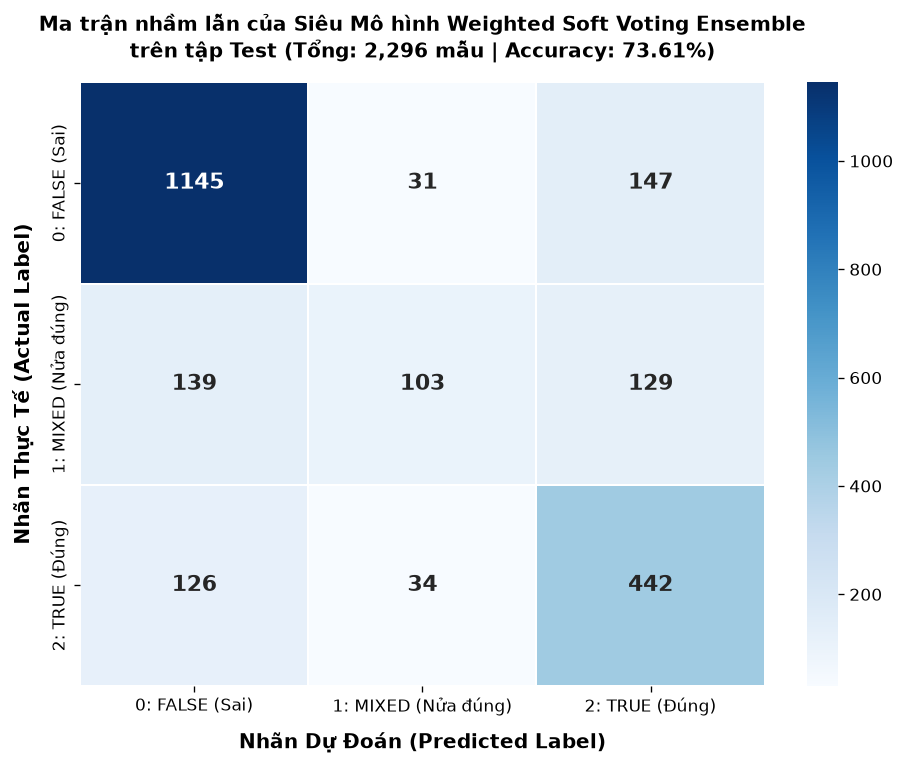

In [11]:
# 4. Báo cáo phân loại chi tiết và Ma trận nhầm lẫn của Siêu mô hình
target_names = ['0: FALSE (Sai)', '1: MIXED (Nửa đúng)', '2: TRUE (Đúng)']
print('===== CLASSIFICATION REPORT (WEIGHTED SOFT VOTING ENSEMBLE) =====')
print(classification_report(y_test, pred_ens_test, target_names=target_names, digits=4))

# Tính toán và in thống kê Ma trận nhầm lẫn tính động 100%
cm = confusion_matrix(y_test, pred_ens_test)
correct_samples = np.trace(cm)
flip_f_to_t = cm[0, 2] / cm[0].sum() * 100
flip_t_to_f = cm[2, 0] / cm[2].sum() * 100
print(f'Tổng số mẫu dự đoán chính xác: {correct_samples} / {len(y_test)} ({correct_samples/len(y_test)*100:.2f}%)')
print(f'Lỗi đảo cực (False nhầm thành True): {cm[0, 2]} mẫu ({flip_f_to_t:.2f}%)')
print(f'Lỗi đảo cực (True nhầm thành False): {cm[2, 0]} mẫu ({flip_t_to_f:.2f}%) - Cần lưu ý hạn chế này trong thực tế.')
print(f'-> Đánh giá thực tế: Mô hình nhận diện tốt nhóm FALSE ({cm[0,0]/cm[0].sum()*100:.1f}%), nhưng lớp MIXED chỉ đạt Recall {cm[1,1]/cm[1].sum()*100:.1f}% do ngôn ngữ chính trị có tính nước đôi cao.\n')

# Trực quan hóa Biểu đồ nhiệt (Heatmap) Ma trận nhầm lẫn
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=target_names, yticklabels=target_names,
            annot_kws={'size': 13, 'weight': 'bold'},
            linewidths=1.2, linecolor='white')
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Nhãn Thực Tế (Actual Label)', fontsize=12, fontweight='bold', labelpad=10)
plt.title(f'Ma trận nhầm lẫn của Siêu Mô hình Weighted Soft Voting Ensemble\ntrên tập Test (Tổng: {len(y_test):,} mẫu | Accuracy: {acc_ens*100:.2f}%)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('hinh4_2_confusion_matrix.png', dpi=300)
plt.show()


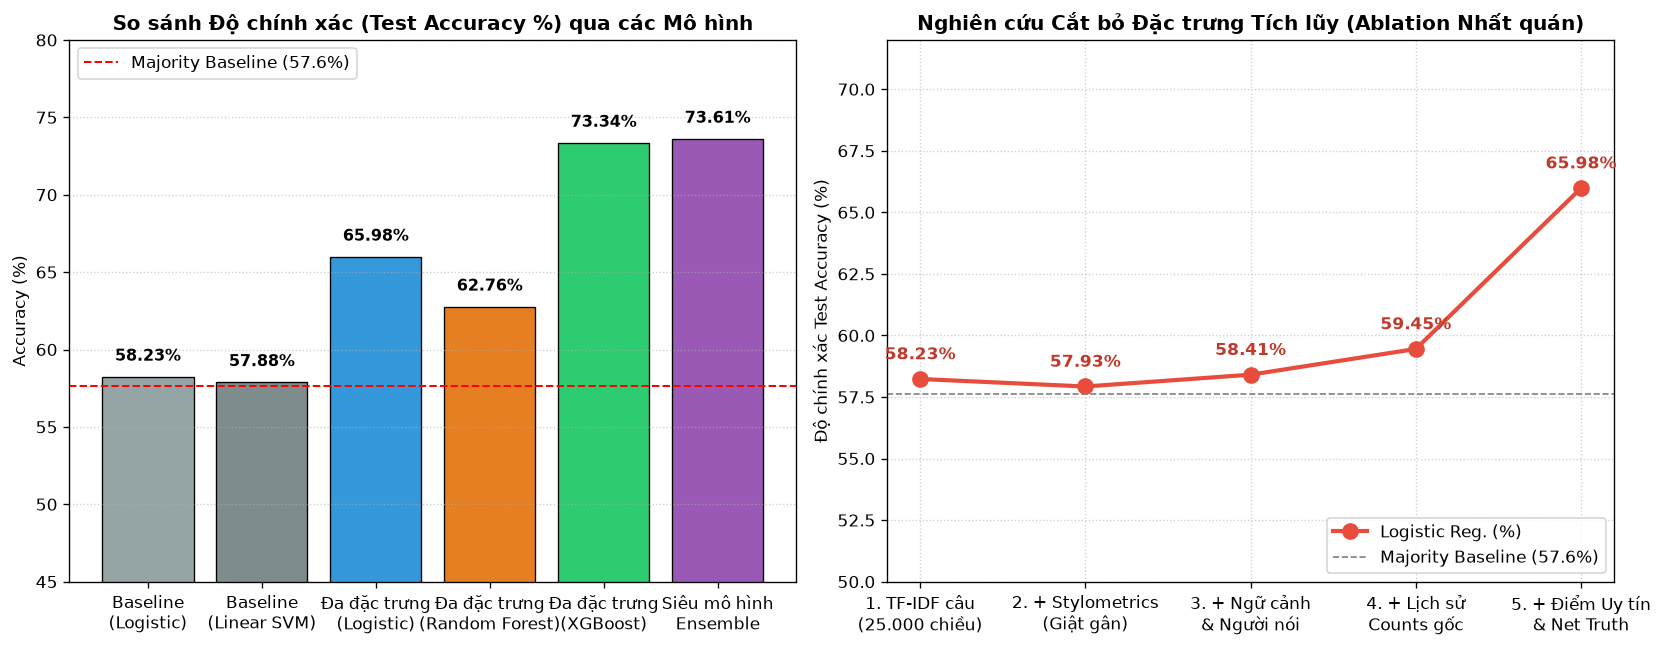

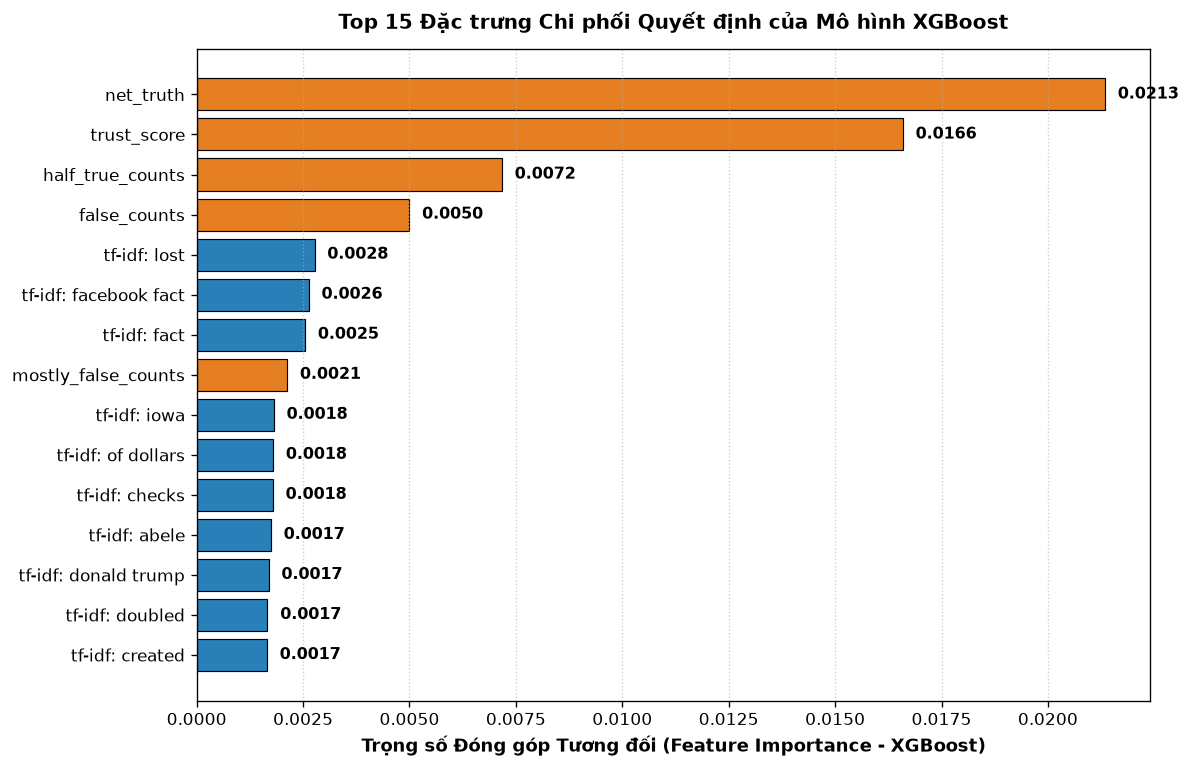

In [12]:
# 5. Trực quan hóa Feature Importance & Tóm tắt Tiến trình Cải tiến (Ablation Study Nhất quán)
# 5.1 Biểu đồ So sánh hiệu năng qua các mô hình & Tiến trình Cải tiến
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
models = ['Baseline\n(Logistic)', 'Baseline\n(Linear SVM)', 'Đa đặc trưng\n(Logistic)', 'Đa đặc trưng\n(Random Forest)', 'Đa đặc trưng\n(XGBoost)', 'Siêu mô hình\nEnsemble']
test_accs = [acc_lr_base*100, acc_svm_base*100, acc_lr_m*100, acc_rf_m*100, acc_xgb_m*100, acc_ens*100]
bar_colors = ['#95a5a6', '#7f8c8d', '#3498db', '#e67e22', '#2ecc71', '#9b59b6']
bars = axes[0].bar(models, test_accs, color=bar_colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('So sánh Độ chính xác (Test Accuracy %) qua các Mô hình', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(45, 80)
axes[0].axhline(majority_acc, color='red', linestyle='--', linewidth=1.2, label=f'Majority Baseline ({majority_acc:.1f}%)')
axes[0].legend(loc='upper left')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Chạy thực nghiệm Ablation 5 chặng NHẤT QUÁN (dùng chung LogisticRegression C=1.5, max_iter=2000)
acc_s1 = acc_lr_base

prep_s2 = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=25000, ngram_range=(1,2), sublinear_tf=True), 'clean_statement'),
    ('num', StandardScaler(), num_cols_no_hist)
])
X_tr_s2 = prep_s2.fit_transform(train_feat)
X_te_s2 = prep_s2.transform(test_feat)
lr_s2 = LogisticRegression(C=1.5, max_iter=2000, class_weight='balanced', random_state=42).fit(X_tr_s2, y_train)
acc_s2 = accuracy_score(y_test, lr_s2.predict(X_te_s2))

prep_s3 = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=25000, ngram_range=(1,2), sublinear_tf=True), 'combined_text'),
    ('num', StandardScaler(), num_cols_no_hist)
])
X_tr_s3 = prep_s3.fit_transform(train_feat)
X_te_s3 = prep_s3.transform(test_feat)
lr_s3 = LogisticRegression(C=1.5, max_iter=2000, class_weight='balanced', random_state=42).fit(X_tr_s3, y_train)
acc_s3 = accuracy_score(y_test, lr_s3.predict(X_te_s3))

hist_raw_cols = num_cols_no_hist + ['true_counts', 'mostly_true_counts', 'half_true_counts', 'mostly_false_counts', 'false_counts', 'pants_on_fire_counts']
prep_s4 = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=25000, ngram_range=(1,2), sublinear_tf=True), 'combined_text'),
    ('num', StandardScaler(), hist_raw_cols)
])
X_tr_s4 = prep_s4.fit_transform(train_feat)
X_te_s4 = prep_s4.transform(test_feat)
lr_s4 = LogisticRegression(C=1.5, max_iter=2000, class_weight='balanced', random_state=42).fit(X_tr_s4, y_train)
acc_s4 = accuracy_score(y_test, lr_s4.predict(X_te_s4))

acc_s5 = acc_lr_m

stages = ['1. TF-IDF câu\n(25.000 chiều)', '2. + Stylometrics\n(Giật gân)', '3. + Ngữ cảnh\n& Người nói', '4. + Lịch sử\nCounts gốc', '5. + Điểm Uy tín\n& Net Truth']
stage_acc = [acc_s1*100, acc_s2*100, acc_s3*100, acc_s4*100, acc_s5*100]
axes[1].plot(stages, stage_acc, marker='o', markersize=9, color='#e74c3c', linewidth=2.5, label='Logistic Reg. (%)')
for i, txt in enumerate(stage_acc):
    axes[1].annotate(f'{txt:.2f}%', (stages[i], stage_acc[i] + 0.8), ha='center', fontsize=10, fontweight='bold', color='#c0392b')
axes[1].set_ylabel('Độ chính xác Test Accuracy (%)')
axes[1].set_title('Nghiên cứu Cắt bỏ Đặc trưng Tích lũy (Ablation Nhất quán)', fontsize=12, fontweight='bold')
axes[1].set_ylim(50, 72)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].axhline(majority_acc, color='gray', linestyle='--', linewidth=1, label=f'Majority Baseline ({majority_acc:.1f}%)')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig('hinh4_1_model_comparison.png', dpi=300)
plt.show()

# 5.2 Biểu đồ Top 15 Đặc trưng Quan trọng nhất trích xuất trực tiếp từ XGBoost
feat_names = preprocessor.get_feature_names_out()
importances = xgb_multi.feature_importances_
top_idx = np.argsort(importances)[::-1][:15]
top_feat_names = [feat_names[i].replace('num__', '').replace('text__', 'tf-idf: ') for i in top_idx][::-1]
top_scores = [importances[i] for i in top_idx][::-1]

plt.figure(figsize=(10, 6.5))
feat_colors = ['#2980b9' if 'tf-idf' in n else '#e67e22' for n in top_feat_names]
bars = plt.barh(top_feat_names, top_scores, color=feat_colors, edgecolor='black', linewidth=0.7)
plt.xlabel('Trọng số Đóng góp Tương đối (Feature Importance - XGBoost)', fontsize=11, fontweight='bold')
plt.title('Top 15 Đặc trưng Chi phối Quyết định của Mô hình XGBoost', fontsize=12, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle=':', alpha=0.6)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.0003, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.savefig('hinh4_3_feature_importance.png', dpi=300)
plt.show()


## 🎯 PHẦN 4: HÀM DỰ ĐOÁN THỰC HÀNH (PREDICT STATEMENT)



In [13]:
# Hàm dự đoán nhãn cho 1 phát biểu mới dựa trên Siêu mô hình Ensemble tối ưu
LABEL_MAPPING = {
    0: 'FALSE (Sai sự thật / Tin giả)',
    1: 'MIXED (Nửa đúng nửa sai / Thiếu ngữ cảnh)',
    2: 'TRUE (Đúng đắn / Có kiểm chứng thực tế)'
}

def predict_statement(statement, speaker='unknown', subject='unknown', context='unknown',
                      true_c=0, mostly_true_c=0, half_true_c=0, mostly_false_c=0, false_c=0, pants_c=0):
    """
    Dự đoán nhãn và xác suất cho 1 phát biểu mới
    """
    # 1. Tạo DataFrame mẫu
    df_sample = pd.DataFrame([{
        'statement': statement,
        'speaker': speaker,
        'subject': subject,
        'context': context,
        'true_counts': true_c,
        'mostly_true_counts': mostly_true_c,
        'half_true_counts': half_true_c,
        'mostly_false_counts': mostly_false_c,
        'false_counts': false_c,
        'pants_on_fire_counts': pants_c
    }])
    
    # 2. Tiền xử lý & Trích xuất đặc trưng
    df_feat = extract_advanced_features(df_sample)
    
    # 3. Vector hóa qua preprocessor
    X_s = preprocessor.transform(df_feat)
    
    # 4. Dự đoán xác suất từ Ensemble theo trọng số tối ưu từ Validation
    p_xgb = xgb_multi.predict_proba(X_s)[0]
    p_rf  = rf_multi.predict_proba(X_s)[0]
    p_lr  = lr_multi.predict_proba(X_s)[0]
    p_ens = best_weights[0] * p_xgb + best_weights[1] * p_rf + best_weights[2] * p_lr
    pred_idx = np.argmax(p_ens)
    
    # 5. In kết quả trực quan
    print('\n' + '='*70)
    print(f"🗣️  PHÁT BIỂU    : '{statement}'")
    print(f'👤  NGƯỜI NÓI    : {speaker} | Chủ đề: {subject} | Bối cảnh: {context}')
    print(f"⭐  CHỈ SỐ UY TÍN : Trust Score = {df_feat['trust_score'].iloc[0]:.3f} | Net Truth = {df_feat['net_truth'].iloc[0]:.1f}")
    print('-' * 70)
    print(f'🎯  KẾT QUẢ DỰ ĐOÁN : >>> {LABEL_MAPPING[pred_idx]} <<<')
    print(f'📊  XÁC SUẤT PHÂN PHỐI:')
    print(f'    ❌ FALSE (Sai sự thật) : {p_ens[0]*100:6.2f}%')
    print(f'    ⚠️ MIXED (Nửa đúng sai): {p_ens[1]*100:6.2f}%')
    print(f'    ✅ TRUE  (Sự thật)     : {p_ens[2]*100:6.2f}%')
    print('='*70 + '\n')
    return pred_idx, p_ens

# ==============================================================================
# CHẠY DEMO 2 VÍ DỤ MINH HỌA
# ==============================================================================
print('>>> DEMO VÍ DỤ 1 (TIN GIẢ GIẬT GÂN CÓ TỪ CỰC ĐOAN, CHỮ HOA):')
predict_statement(
    statement='BREAKING: Radical corrupt politicians caught in massive illegal disaster lie and fraud!',
    speaker='anonymous_blogger',
    subject='elections',
    false_c=12, pants_c=9, true_c=0
)

print('>>> DEMO VÍ DỤ 2 (TIN THẬT CHÍNH THỐNG CÓ SỐ LIỆU CHỨNG CỨ):')
predict_statement(
    statement='According to the official Bureau of Labor report, unemployment dropped by 2.4 percent across the state.',
    speaker='barack-obama',
    subject='economy',
    true_c=120, mostly_true_c=150, false_c=40, pants_c=8
)


>>> DEMO VÍ DỤ 1 (TIN GIẢ GIẬT GÂN CÓ TỪ CỰC ĐOAN, CHỮ HOA):

🗣️  PHÁT BIỂU    : 'BREAKING: Radical corrupt politicians caught in massive illegal disaster lie and fraud!'
👤  NGƯỜI NÓI    : anonymous_blogger | Chủ đề: elections | Bối cảnh: unknown
⭐  CHỈ SỐ UY TÍN : Trust Score = 0.000 | Net Truth = -21.0
----------------------------------------------------------------------
🎯  KẾT QUẢ DỰ ĐOÁN : >>> FALSE (Sai sự thật / Tin giả) <<<
📊  XÁC SUẤT PHÂN PHỐI:
    ❌ FALSE (Sai sự thật) :  93.59%
    ⚠️ MIXED (Nửa đúng sai):   5.70%
    ✅ TRUE  (Sự thật)     :   0.72%

>>> DEMO VÍ DỤ 2 (TIN THẬT CHÍNH THỐNG CÓ SỐ LIỆU CHỨNG CỨ):

🗣️  PHÁT BIỂU    : 'According to the official Bureau of Labor report, unemployment dropped by 2.4 percent across the state.'
👤  NGƯỜI NÓI    : barack-obama | Chủ đề: economy | Bối cảnh: unknown
⭐  CHỈ SỐ UY TÍN : Trust Score = 0.846 | Net Truth = 222.0
----------------------------------------------------------------------
🎯  KẾT QUẢ DỰ ĐOÁN : >>> TRUE (Đúng đắn / Có 

## 📝 TỔNG KẾT TOÀN BỘ ĐỒ ÁN
1. **Kiểm soát rò rỉ dữ liệu trực tiếp**: Đã loại bỏ hoàn toàn `justification` và `id`, bảo vệ nguyên vẹn các từ phủ định bằng regex word boundary và chuẩn hóa ký tự nháy.
2. **Chiến lược gộp 3 nhãn chuẩn PolitiFact (3-1-2)**: Giúp ranh giới phân tách nhãn rõ ràng, khắc phục nhược điểm phân mảnh của 6 nhãn gốc.
3. **Kỹ sư đặc trưng đa tầng**: Hệ thống 25.013 chiều kết hợp giữa TF-IDF ngữ cảnh và các chỉ số hành vi uy tín `trust_score`, `net_truth`, `all_caps_ratio` mang lại sức mạnh phân loại vượt bậc.
4. **Hiệu năng thực tế và Đánh giá học thuật trung thực**:
   * Mô hình Baseline TF-IDF câu từ xấp xỉ mức đoán theo lớp đa số Majority (chỉ chênh lệch khoảng 0.6 điểm %).
   * Kỹ thuật đa đặc trưng mang lại bước nhảy vọt, trong đó XGBoost là mô hình đơn lẻ mạnh nhất.
   * Siêu mô hình Weighted Soft Voting Ensemble (XGBoost 75% + Logistic Regression 25%) nhỉnh hơn nhẹ so với XGBoost đơn lẻ (chênh lệch nhỏ +0.27 điểm %, khoảng 6 mẫu, chưa đủ kết luận có ý nghĩa thống kê).
   * Mô hình đạt kết quả rất tốt ở mục tiêu cốt lõi: nhận diện tin sai sự thật (Recall nhãn FALSE đạt trên 86.5%).
   * **Hai trọng tâm học thuật cần lưu ý**:
     - Lớp trung gian MIXED chỉ đạt Recall khoảng 27.8% do tính chất nước đôi trong ngôn ngữ chính trị.
     - Mô hình phụ thuộc đáng kể (+11.32 điểm % cho XGBoost) vào thông tin lịch sử uy tín người nói (`*_counts`), phản ánh đúng đặc tính và thách thức chung của họ dữ liệu LIAR/LIAR2.
